In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from warnings import filterwarnings

In [4]:
df = pd.read_csv(r"C:\Users\srini\OneDrive\Desktop\50 days projects\Data analysis\train.csv")

In [5]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [6]:
df.shape

(891, 12)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [8]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [21]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [15]:
df.isnull().mean() * 100

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64

In [ ]:
# Handeling Age
df['Age'] = df['Age'].fillna(df['Age'].median())
# Handeling Cabin
df.drop('Cabin', axis=1, inplace=True)
#Handeling Embarked
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [11]:
df.duplicated().sum()

0

In [25]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

### Survival Analysis


In [28]:
df['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [30]:
df['Survived'].value_counts(normalize=True) * 100

Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

### 38% of people are survived

C:\Users\srini\AppData\Local\Temp\ipykernel_15948\2326585081.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Survived', palette='Set2')


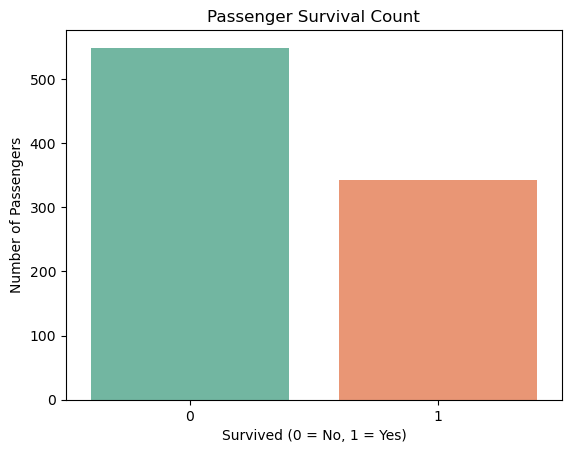

In [33]:
sns.countplot(data=df, x='Survived', palette='Set2')
plt.title('Passenger Survival Count')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Number of Passengers')
plt.show()

## Gender wise survival Analysos

In [34]:
df['Sex'].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [35]:
df.groupby('Sex')['Survived'].mean() * 100

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

C:\Users\srini\AppData\Local\Temp\ipykernel_15948\1331461151.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Sex', y='Survived', palette='Set1')


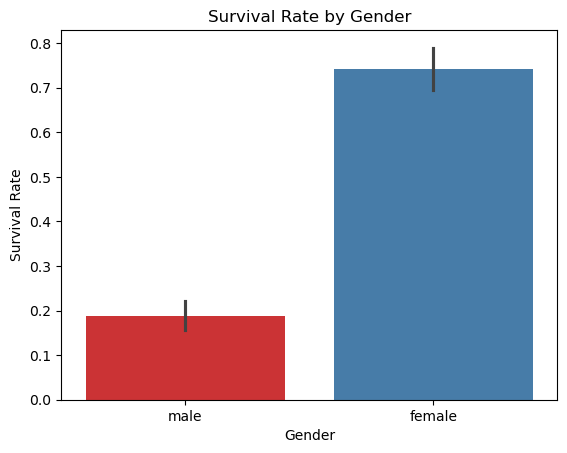

In [36]:
sns.barplot(data=df, x='Sex', y='Survived', palette='Set1')
plt.title('Survival Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Survival Rate')
plt.show()

## Passenger Analysos

In [37]:
df['Pclass'].value_counts().sort_index()

Pclass
1    216
2    184
3    491
Name: count, dtype: int64

In [38]:
df.groupby('Pclass')['Survived'].mean() * 100

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

C:\Users\srini\AppData\Local\Temp\ipykernel_15948\156826060.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Pclass', y='Survived', palette='viridis')


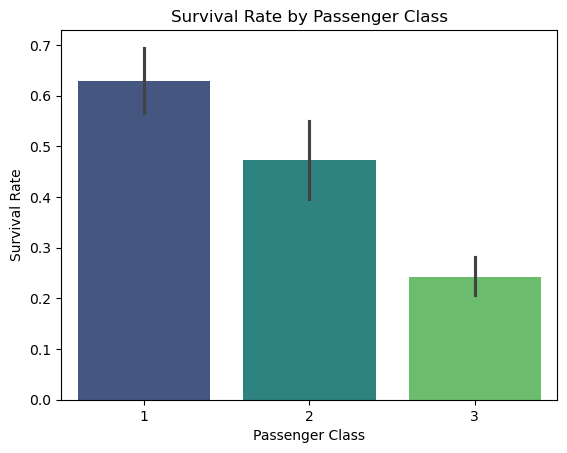

In [39]:
sns.barplot(data=df, x='Pclass', y='Survived', palette='viridis')
plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.show()

### Age wise analysios

In [41]:
df['Age_Group'] = pd.cut(df['Age'],bins=[0, 12, 18, 35, 60, 100],
                         labels=['Child', 'Teenager', 'Adult', 'Middle Aged', 'Senior'])

In [42]:
df['Age_Group'].value_counts()

Age_Group
Adult          535
Middle Aged    195
Teenager        70
Child           69
Senior          22
Name: count, dtype: int64

In [43]:
df.groupby('Age_Group', observed=False)['Survived'].mean() * 100

Age_Group
Child          57.971014
Teenager       42.857143
Adult          35.327103
Middle Aged    40.000000
Senior         22.727273
Name: Survived, dtype: float64

C:\Users\srini\AppData\Local\Temp\ipykernel_15948\1578332480.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Age_Group', y='Survived', palette='coolwarm')


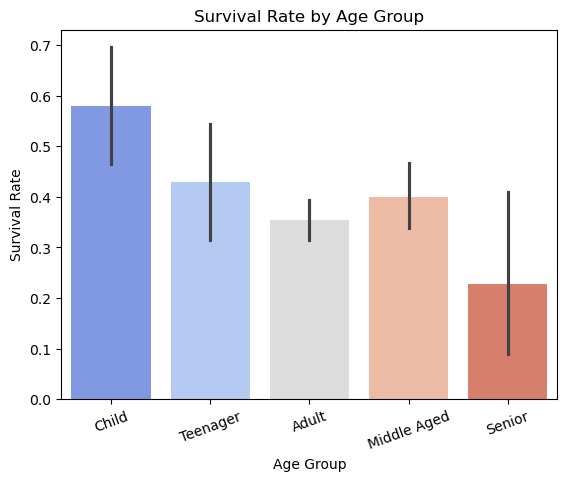

In [45]:
sns.barplot(data=df, x='Age_Group', y='Survived', palette='coolwarm')
plt.title('Survival Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Survival Rate')
plt.xticks(rotation=20)
plt.show()

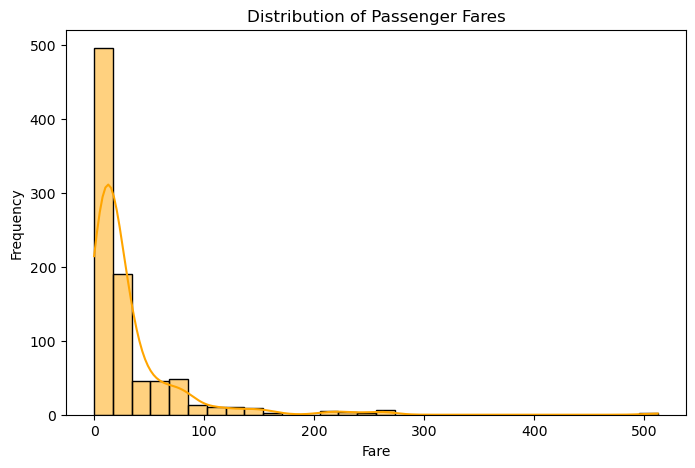

In [48]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x='Fare', bins=30, kde=True, color='orange')
plt.title('Distribution of Passenger Fares')
plt.xlabel('Fare')
plt.ylabel('Frequency')
plt.show()
# Fare distributuion

### Combined Analysis

In [50]:
pd.pivot_table(df,values='Survived',index='Sex',columns='Pclass',aggfunc='mean') * 100

Pclass,1,2,3
Sex,,,
female,96.808511,92.105263,50.000000
male,36.885246,15.740741,13.544669


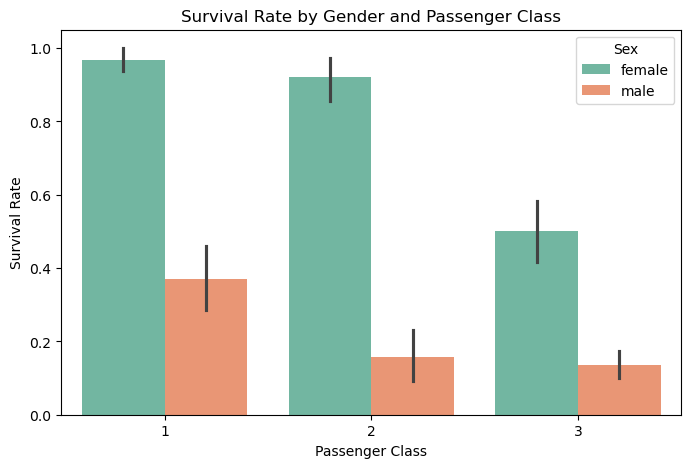

In [52]:
plt.figure(figsize=(8,5))
sns.barplot(data=df, x='Pclass', y='Survived', hue='Sex', palette='Set2')
plt.title('Survival Rate by Gender and Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.show()

In [54]:
df['Family_Size'] = df['SibSp'] + df['Parch'] + 1
df['Travelling_Alone'] = df['Family_Size'].apply(lambda x: 'Solo' if x == 1 else 'With Family')
df.groupby('Travelling_Alone')['Survived'].mean() * 100

Travelling_Alone
Solo           30.353818
With Family    50.564972
Name: Survived, dtype: float64

In [55]:
df.groupby('Pclass')['Survived'].mean() * 100

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

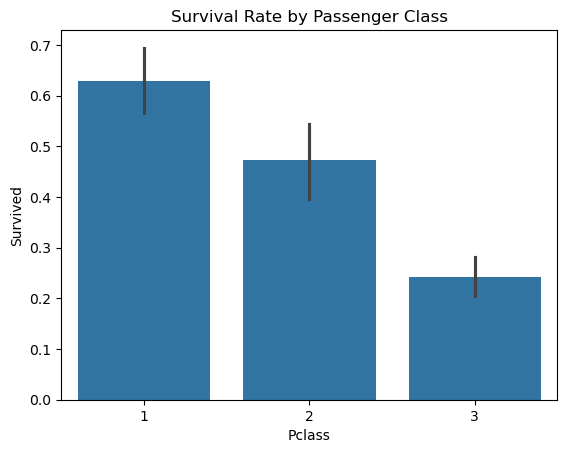

In [56]:
sns.barplot(data=df, x='Pclass', y='Survived')
plt.title('Survival Rate by Passenger Class')
plt.show()

In [57]:
df.groupby('Sex')['Survived'].mean() * 100

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

# Questions

1. Which gender had the highest survival rate?
2. Which passenger class had the highest survival rate?
3. Which age group had the highest survival rate?
4. Did passengers travelling with family have a different survival rate from solo travellers?
5. Did passenger fare or class appear to be associated with survival?
6. Which passenger group was more likely to survive overall?

#### 1-Female 
#### 2-2nd passenger class had highest survival rate
#### 3-'Child' age group had highest survival rate
#### 4-travelling with family generally had a higher survival rate than solo travellers.
#### 5-First-class passengers had a higher survival rate than second- and third-class passengers.
#### 6-Female passengers were significantly more likely to survive than male passengers.